# GPT-2, reward model и RL: полный эксперимент

Порядок: данные → GPT-2 и простые стратегии → варианты reward model → RL с разными наградами → пять шагов и контроль декодирования → многошаговый RL → KL.

По умолчанию загружаем готовые модели. Все флаги обучения ниже выключены: `Run All` пересчитывает оценки и строит графики, но не обучает модели. Результаты для отчёта сохраняются в `artifacts/report_exports/`. Для полного запуска нужны исходный baseline, все reward-модели и папки RL-запусков из предыдущих экспериментов. На Kaggle подключите их как Input.

Ячейки воспроизведения обучения бейзлайна и reward models сохранены под отдельными флагами и пишут в отдельные папки `*_reproduction_seed42`. Основные сравнения используют зафиксированные исходные артефакты. При включении `RUN_RL_TRAINING` RL-запуски выполняются заново; для подготовки отчёта это не требуется.


In [ ]:
from pathlib import Path

# Локально репозиторий уже открыт. В Colab/Kaggle загружаем его с GitHub.
hosted = Path("/kaggle/working").is_dir() or Path("/content").is_dir()
if hosted:
    work_dir = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path("/content")
    repo_dir = work_dir / "recsys-rl-sequential"
    if repo_dir.exists():
        !git -C {repo_dir} pull --ff-only
    else:
        !git clone https://github.com/daosistt/recsys-rl-sequential {repo_dir}
    %cd {repo_dir}
    %pip install -q -r requirements.txt
else:
    # Локально работаем из корня проекта.
    repo_dir = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
    %cd {repo_dir}


In [ ]:
from src import config as project_config

project_config.setup_paths()
from src.config import *
from src.prepare_data import load_yambda_data, train_val_test_split
from src.evaluation import load_model
from src.reward_model import clear_memory
from src.reward import prepare_track_statistics
from src.reinforce import prepare_rl_contexts, train_reinforce

print(f"Данные: {DATA_DIR}")
print(f"Результаты: {ARTIFACTS_DIR}")
print(f"Устройство: {device}")


In [ ]:
baseline_dir = find_artifact_dir("baseline_t4_1000_minfreq5")
reward_dir = find_artifact_dir("reward_catboost_stats_minfreq5")

print(f"Бейзлайн: {baseline_dir}")
print(f"Reward model: {reward_dir}")


In [ ]:
REPORT_DIR = ARTIFACTS_DIR / "report_exports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_BASELINE = False
TRAIN_REWARD = False
RUN_RL_TRAINING = False
print(f"Таблицы и графики: {REPORT_DIR}")


## Данные и GPT-2 бейзлайн

Берём первые 1000 историй, используем сохранённые общие временные границы. Словарь строится только по train, частота ≥5. Воспроизведение обучения опционально: новая модель не заменяет зафиксированный baseline. В оценке — первый test-трек пользователя, неизвестные цели остаются промахами.


In [5]:
from src.vocabulary import Vocabulary
from src.dataset import RecDataset
from src.train import train_loop
from src.evaluation import prepare_evaluation_data, recommend_top_k, evaluate_metrics, compare_baselines

with open(baseline_dir / "experiment_config.json") as f:
    baseline_config = json.load(f)
report_df = load_yambda_data(size=baseline_config["training"]["data_size"])
report_train, report_val, report_test = train_val_test_split(report_df, **baseline_config["split"])
del report_df
clear_memory()
data_summary = pd.DataFrame({
    name: {"Users": len(frame), "Events": sum(map(len, frame.item_id))}
    for name, frame in (("train", report_train), ("val", report_val), ("test", report_test))
}).T
data_summary.to_csv(REPORT_DIR / "data_summary.csv")
data_summary


,Users,Events
train,901,3677916
val,901,584811
test,901,619135


In [6]:
if TRAIN_BASELINE:
    training = baseline_config["training"]
    torch.manual_seed(training["seed"])
    np.random.seed(training["seed"])
    new_vocab = Vocabulary(report_train, min_frequency=training["min_frequency"])
    model_params = {**baseline_config["model"], "vocab_size": len(new_vocab), "pad_token_id": new_vocab.pad_idx}
    new_model = GPT2LMHeadModel(GPT2Config(**model_params)).to(device)
    train_dataset = RecDataset(report_train, new_vocab, model_params["n_positions"])
    val_dataset = RecDataset(report_val, new_vocab, model_params["n_positions"], context=report_train)
    train_loader = DataLoader(train_dataset, batch_size=training["batch_size"], shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=training["batch_size"])
    optimizer = AdamW(new_model.parameters(), lr=training["lr"], weight_decay=training["weight_decay"])
    reproduction_dir = ARTIFACTS_DIR / "baseline_reproduction_seed42"
    reproduction_dir.mkdir(parents=True, exist_ok=True)
    with open(reproduction_dir / "vocab.pkl", "wb") as f:
        pickle.dump(new_vocab, f)
    with open(reproduction_dir / "experiment_config.json", "w") as f:
        json.dump(baseline_config, f, indent=2)
    train_loop(new_model, train_loader, val_loader, optimizer, device=device,
               num_epochs=training["num_epochs"], checkpoint_dir=reproduction_dir / "checkpoints",
               plot_every=training["plot_every"])
    del new_model, optimizer, train_loader, val_loader, train_dataset, val_dataset
    clear_memory()
else:
    print("Повторное обучение бейзлайна выключено; используем зафиксированные веса.")


Повторное обучение бейзлайна выключено; используем зафиксированные веса.


In [7]:
report_model, report_vocab, baseline_config = load_model(baseline_dir, device)
report_contexts, report_targets = prepare_evaluation_data(
    report_train, report_val, report_test, report_vocab, report_model.config.n_positions,
)
report_recommendations = recommend_top_k(report_model, report_contexts, report_vocab, k=20, batch_size=32)
baseline_metrics = compare_baselines(
    report_train, report_val, report_test, report_vocab, report_targets,
    evaluate_metrics(report_recommendations, report_targets),
)
baseline_metrics.to_csv(REPORT_DIR / "baseline_comparison.csv")
print(f"Словарь: {len(report_vocab)-2} треков; test-примеров: {len(report_targets)}")
print(f"Неизвестных целей: {np.mean([row[0] not in report_vocab for row in report_targets]):.1%}")
baseline_metrics


Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

Словарь: 86239 треков; test-примеров: 897
Неизвестных целей: 30.7%


Recall@K    NDCG@K     MAP@K
Model              K                               
Popularity         5   0.002230  0.001184  0.000836
                   10  0.004459  0.001903  0.001133
                   20  0.015608  0.004815  0.001980
Personal frequency 5   0.047938  0.036564  0.032776
                   10  0.065775  0.042137  0.034961
                   20  0.093645  0.049267  0.036964
GPT-2              5   0.049052  0.035263  0.030676
                   10  0.071349  0.042439  0.033616
                   20  0.094760  0.048353  0.035237

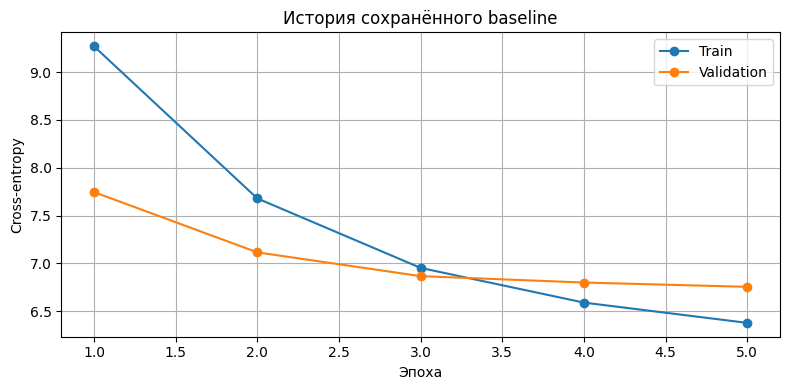

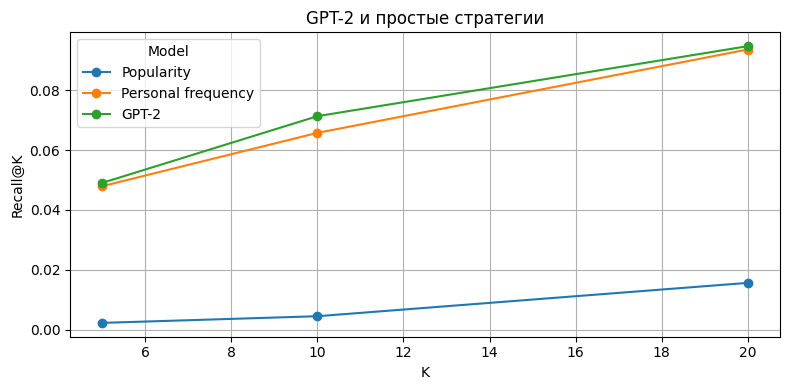

In [8]:
checkpoint = torch.load(baseline_dir / "checkpoints/best.pt", map_location="cpu", weights_only=True)
baseline_history = checkpoint["loss_history"]
del checkpoint
clear_memory()
fig, ax = plt.subplots(figsize=(8, 4))
for key, label in (("train_epoch", "Train"), ("val_epoch", "Validation")):
    values = baseline_history[key]
    ax.plot(range(1, len(values)+1), values, marker="o", label=label)
ax.set(xlabel="Эпоха", ylabel="Cross-entropy", title="История сохранённого baseline")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(REPORT_DIR / "baseline_loss.svg", bbox_inches="tight")
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 4))
baseline_metrics["Recall@K"].unstack("Model").plot(ax=ax, marker="o")
ax.set(ylabel="Recall@K", title="GPT-2 и простые стратегии")
ax.grid(True)
fig.tight_layout()
fig.savefig(REPORT_DIR / "baseline_comparison.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


## Сравнение reward models

Цель — `played_ratio_pct / 100`, без обрезания выше 1. Случайные подвыборки: 20 000 train, по 5000 validation/test; только известные целевые треки с предшествующей историей. Пять статистик считают отклики строго до события. Это rolling-оценка отклика; она отличается от оценки первого next-item на пользователя.

По умолчанию читаем сохранённые метрики. Опциональная ячейка ниже воспроизводит Ridge и три варианта CatBoost, не заменяя выбранные модели. Далее отдельно переоцениваем сохранённую размороженную модель, чтобы получить актуальные результаты по её весам.


In [9]:
from src.reward_model import (
    prepare_reward_features, prepare_reward_tabular, fit_reward_head,
    fit_reward_catboost, evaluate_reward_head, save_reward_model,
)

if TRAIN_REWARD:
    reward_features, reward_targets, reward_items = prepare_reward_features(
        report_model, report_vocab, report_train, report_val, report_test, REWARD_PARAMS,
    )
    tabular = prepare_reward_tabular(
        report_train, report_val, report_test, report_vocab, report_model.config.n_positions, REWARD_PARAMS,
    )
    enriched = {name: np.column_stack((reward_features[name], tabular[name])) for name in reward_features}
    ridge = fit_reward_head(reward_features, reward_targets)
    cb = fit_reward_catboost(reward_features, reward_targets, REWARD_CATBOOST_PARAMS)
    cb_stats = fit_reward_catboost(enriched, reward_targets, REWARD_CATBOOST_PARAMS)
    cb_tabular = fit_reward_catboost(tabular, reward_targets, REWARD_CATBOOST_PARAMS)
    reproduced_metrics = evaluate_reward_head(
        ridge, reward_features, reward_targets, report_train, reward_items,
        extra_heads={"GPT-2 + CatBoost": cb, "GPT-2 + stats + CatBoost": cb_stats, "Stats + CatBoost": cb_tabular},
        extra_features={"GPT-2 + stats + CatBoost": enriched, "Stats + CatBoost": tabular},
    )
    for name, head, names in (
        ("ridge", ridge, [f"gpt_{i}" for i in range(report_model.config.n_embd)]),
        ("catboost", cb, [f"gpt_{i}" for i in range(report_model.config.n_embd)]),
        ("catboost_stats", cb_stats, [f"gpt_{i}" for i in range(report_model.config.n_embd)] + REWARD_EXTRA_FEATURE_NAMES),
        ("catboost_tabular", cb_tabular, REWARD_EXTRA_FEATURE_NAMES),
    ):
        save_reward_model(head, reproduced_metrics, ARTIFACTS_DIR / "reward_reproduction_seed42" / name,
                          baseline_dir, baseline_config, REWARD_PARAMS, reward_targets["train"], names)
    del reward_features, reward_targets, reward_items, tabular, enriched, ridge, cb, cb_stats, cb_tabular
    clear_memory()
else:
    print("Повторное обучение reward models выключено.")


Повторное обучение reward models выключено.


In [10]:
reward_results_dir = find_artifact_dir("reward_catboost_tabular_minfreq5")
reward_comparison = pd.read_csv(reward_results_dir / "metrics.csv", index_col=["Split", "Model"])
reward_comparison.to_csv(REPORT_DIR / "reward_comparison.csv")
reward_comparison


MAE (п.п.)  RMSE (п.п.)
Split Model                                            
val   Train mean                 42.338769    44.520226
      Track mean                 39.140700    43.634096
      GPT-2 + Ridge              38.936168    42.620201
      GPT-2 + CatBoost           37.839375    41.676972
      GPT-2 + stats + CatBoost   32.989839    38.827078
      Stats + CatBoost           33.124750    39.032933
test  Train mean                 42.249680    44.425908
      Track mean                 39.011006    43.762090
      GPT-2 + Ridge              38.607597    42.581903
      GPT-2 + CatBoost           37.710618    41.652572
      GPT-2 + stats + CatBoost   33.089835    39.114508
      Stats + CatBoost           33.231199    39.385200

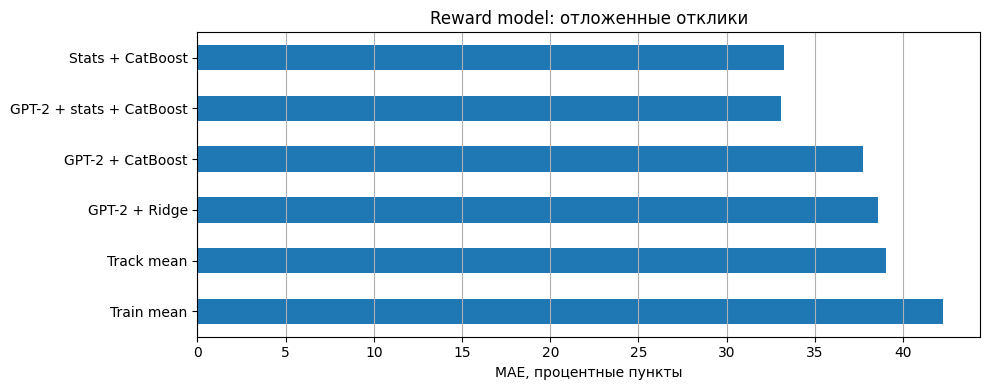

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
reward_comparison.xs("test")["MAE (п.п.)"].plot.barh(ax=ax)
ax.set(xlabel="MAE, процентные пункты", ylabel="", title="Reward model: отложенные отклики")
ax.grid(True, axis="x")
fig.tight_layout()
fig.savefig(REPORT_DIR / "reward_comparison.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


In [12]:
from src.reward_finetuning import load_unfrozen_reward, prepare_reward_loaders, evaluate_unfrozen_reward

unfrozen_dir = find_artifact_dir("reward_unfrozen_minfreq5")
unfrozen_model, unfrozen_experiment = load_unfrozen_reward(unfrozen_dir, device)
unfrozen_loaders = prepare_reward_loaders(
    report_train, report_val, report_test, report_vocab, unfrozen_model.config.n_positions,
    unfrozen_experiment["ridge_config"]["sampling"], batch_size=64,
)
unfrozen_rows = []
for split in ("val", "test"):
    unfrozen_rows.append({"Split": split, "Model": "Unfrozen GPT-2 + linear",
                          **evaluate_unfrozen_reward(unfrozen_model, unfrozen_loaders[split])})
unfrozen_metrics = pd.DataFrame(unfrozen_rows).set_index(["Split", "Model"])
updated_cb_dir = find_artifact_dir("reward_catboost_unfrozen_stats_minfreq5")
updated_cb_metrics = pd.read_csv(updated_cb_dir / "metrics.csv", index_col=["Split", "Model"])
updated_cb_metrics = updated_cb_metrics.loc[
    updated_cb_metrics.index.get_level_values("Model") == "Unfrozen GPT-2 + stats + CatBoost"
]
unfreezing_comparison = pd.concat([reward_comparison, unfrozen_metrics, updated_cb_metrics])
unfreezing_comparison.to_csv(REPORT_DIR / "reward_unfreezing_comparison.csv")
del unfrozen_model, unfrozen_loaders, report_model, report_train, report_val, report_test
clear_memory()
unfreezing_comparison


Reward checkpoint: эпоха 3, validation MAE=38.419 п.п.
Выбрано 20000 из 3431203 подходящих событий (всего 3677916)
Выбрано 5000 из 484422 подходящих событий (всего 584811)
Выбрано 5000 из 467582 подходящих событий (всего 619135)


MAE (п.п.)  RMSE (п.п.)
Split Model                                                     
val   Train mean                          42.338769    44.520226
      Track mean                          39.140700    43.634096
      GPT-2 + Ridge                       38.936168    42.620201
      GPT-2 + CatBoost                    37.839375    41.676972
      GPT-2 + stats + CatBoost            32.989839    38.827078
      Stats + CatBoost                    33.124750    39.032933
test  Train mean                          42.249680    44.425908
      Track mean                          39.011006    43.762090
      GPT-2 + Ridge                       38.607597    42.581903
      GPT-2 + CatBoost                    37.710618    41.652572
      GPT-2 + stats + CatBoost            33.089835    39.114508
      Stats + CatBoost                    33.231199    39.385200
val   Unfrozen GPT-2 + linear             38.418505    42.406578
test  Unfrozen GPT-2 + linear             38.468639    42.575185
      Unfrozen GPT-2 + stats + CatBoost   33.077522    39.128097
val   Unfrozen GPT-2 + stats + CatBoost   33.006278    38.913539

## REINFORCE: один следующий трек

Политика выбирает трек случайно из своего распределения, исключая PAD и UNK. Награду считает зафиксированный CatBoost на эмбеддингах исходной GPT-2 и пяти признаках.

Минимизируем `-mean((reward - baseline) * log_prob) + kl_coef * KL(policy || reference)`. Baseline — награда жадного выбора исходной GPT-2 для того же контекста. Dropout отключён, градиенты политики сохраняются. Замороженная исходная GPT-2 также используется для эмбеддингов reward model.

В `RL_PARAMS` доступны награды `listening`, `repeat_penalty`, `popularity_penalty`; `penalty` задаёт штраф, `kl_coef` — силу ограничения отклонения от бейзлайна. Для каждого варианта заново выполняем загрузку моделей: все запуски начинаются с одного бейзлайна.

Контексты обучения берём из train. Validation и её seed фиксированы; лучший чекпоинт выбирается по `val_reward - kl_coef * val_kl`, включая исходную эпоху 0. Это оценка по reward model. Test используется ниже только для сравнения релевантности и поведения, а не в функции обучения.



In [ ]:
params = RL_PARAMS.copy()
params["reward_type"] = "repeat_penalty"
torch.manual_seed(params["seed"])
np.random.seed(params["seed"])

# Каждый вариант награды начинаем с двух отдельных копий исходного бейзлайна.
policy, vocab, baseline_config = load_model(baseline_dir, device)
reference, _, _ = load_model(baseline_dir, device)
reference.requires_grad_(False)
with open(reward_dir / "reward_head.pkl", "rb") as f:
    reward_head = pickle.load(f)
with open(reward_dir / "config.json") as f:
    reward_config = json.load(f)
assert reward_config["backbone_run"] == baseline_dir.name
assert reward_config["split"] == baseline_config["split"]

run_name = f"rl_{params['reward_type']}_seed{params['seed']}"
rl_source_dir = ARTIFACTS_DIR / run_name if RUN_RL_TRAINING else find_artifact_dir(run_name)
output_dir = rl_source_dir if RUN_RL_TRAINING else REPORT_DIR / f"evaluation_{run_name}"
output_dir.mkdir(parents=True, exist_ok=True)
experiment = {"baseline_run": baseline_dir.name, "reward_run": reward_dir.name,
              "baseline_config": baseline_config}
print(f"Награда: {params['reward_type']}, KL: {params['kl_coef']}")
print(f"Сохраним в: {output_dir}")


In [14]:
df = load_yambda_data(size=baseline_config["training"]["data_size"])
train, val, test = train_val_test_split(df, **baseline_config["split"])
del df, test
clear_memory()

statistics = prepare_track_statistics(train)
train_contexts = prepare_rl_contexts(train, vocab, params["train_samples"], params["seed"])
val_contexts = prepare_rl_contexts(val, vocab, params["val_samples"], params["seed"], context=train)
del train, val
clear_memory()
print(f"Контексты: train={len(train_contexts)}, validation={len(val_contexts)}")


Выбрано 5000 из 3431203 подходящих событий (всего 3677916)
Выбрано 512 из 484422 подходящих событий (всего 584811)
Контексты: train=5000, validation=512


In [15]:
if RUN_RL_TRAINING:
    history = train_reinforce(
        policy, reference, reward_head, vocab, train_contexts, val_contexts,
        statistics, params, output_dir, experiment,
    )
else:
    checkpoint = torch.load(rl_source_dir / "checkpoints/best.pt", map_location="cpu", weights_only=True)
    policy.load_state_dict(checkpoint["model_state_dict"])
    del checkpoint
    history = pd.read_csv(rl_source_dir / "history.csv")
history


,epoch,val_reward,val_ratio,val_reference_reward,val_kl,val_loss,val_objective,train_reward,train_ratio,train_reference_reward,train_kl,train_loss,train_objective
0,0,0.548572,0.604822,0.53961,0.000000,0.090765,0.548572,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.553798,0.608486,0.53961,0.013794,0.130867,0.553109,0.574915,0.632735,0.559282,0.003651,0.145797,0.574733
2,2,0.556323,0.610425,0.53961,0.040541,0.147079,0.554296,0.577779,0.634739,0.559282,0.019906,0.164745,0.576784


In [16]:
from src.evaluation import prepare_evaluation_data, recommend_top_k, evaluate_metrics
from src.reinforce import score_actions

# Явно восстанавливаем лучший RL-чекпоинт.
checkpoint = torch.load(
    rl_source_dir / "checkpoints/best.pt",
    map_location="cpu", weights_only=True,
)
policy.load_state_dict(checkpoint["model_state_dict"])
eval_params = checkpoint["params"].copy()
print(f"RL: эпоха {checkpoint['epoch']}")
del checkpoint

df = load_yambda_data(size=baseline_config["training"]["data_size"])
eval_train, eval_val, eval_test = train_val_test_split(
    df, **baseline_config["split"],
)
del df

contexts, targets = prepare_evaluation_data(
    eval_train, eval_val, eval_test, vocab, policy.config.n_positions,
)

# Полные истории нужны для пяти признаков и проверки знакомых треков.
columns = ("item_id", "timestamp", "played_ratio_pct")
histories = {
    row.uid: {col: np.asarray(getattr(row, col)) for col in columns}
    for row in eval_train.itertuples(index=False)
}
for row in eval_val.itertuples(index=False):
    for col in columns:
        histories[row.uid][col] = np.concatenate(
            (histories[row.uid][col], getattr(row, col))
        )

reward_contexts = [
    {"history": histories[row.uid], "query_time": int(row.timestamp[0])}
    for row in eval_test.itertuples(index=False) if len(row.item_id)
]
del eval_train, eval_val, eval_test, histories
clear_memory()

recommendations = {
    "Baseline": recommend_top_k(reference, contexts, vocab, k=20, batch_size=32),
    "RL": recommend_top_k(policy, contexts, vocab, k=20, batch_size=32),
}
metrics = pd.concat(
    {name: evaluate_metrics(recs, targets) for name, recs in recommendations.items()},
    names=["Model"],
)
metrics.to_csv(output_dir / "test_ranking_metrics.csv")
print(f"Test-примеров: {len(targets)}")
metrics


RL: эпоха 2


Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

Test-примеров: 897


Recall@K    NDCG@K     MAP@K
Model    K                               
Baseline 5   0.049052  0.035263  0.030676
         10  0.071349  0.042439  0.033616
         20  0.094760  0.048353  0.035237
RL       5   0.047938  0.036469  0.032683
         10  0.064660  0.041982  0.035021
         20  0.094760  0.049490  0.037028

In [17]:
seen_items = [set(c["history"]["item_id"]) for c in reward_contexts]
rows = []

for name, recs in recommendations.items():
    rewards, ratios = [], []

    # Оцениваем первый рекомендованный трек в исходном контексте.
    for start in tqdm(range(0, len(recs), 32), desc=f"Reward: {name}"):
        batch_recs = recs[start:start + 32]
        batch_contexts = reward_contexts[start:start + 32]
        actions = torch.tensor(
            vocab.encode([rec[0] for rec in batch_recs]),
            dtype=torch.long,
        ) - 2

        batch_rewards, batch_ratios = score_actions(
            reference, reward_head, vocab, batch_contexts,
            actions, statistics, eval_params,
        )
        rewards.extend(batch_rewards)
        ratios.extend(batch_ratios)

    counts = Counter(item for rec in recs for item in rec)
    n = len(recs)
    k = len(recs[0])

    # Средняя доля общих треков в top-20 для пары разных пользователей.
    overlap = sum(count * (count - 1) for count in counts.values())
    overlap /= n * (n - 1) * k

    rows.append({
        "Model": name,
        "Predicted ratio@1": np.mean(ratios),
        "Reward@1": np.mean(rewards),
        "Seen@20 (%)": 100 * np.mean([
            item in seen
            for rec, seen in zip(recs, seen_items) for item in rec
        ]),
        "Catalog coverage@20 (%)": 100 * len(counts) / (len(vocab) - 2),
        "Overlap@20 (%)": 100 * overlap,
        "Mean popularity@20": np.mean([
            statistics["popularity"][item] for rec in recs for item in rec
        ]),
    })

behavior = pd.DataFrame(rows).set_index("Model")
behavior.to_csv(output_dir / "test_behavior_metrics.csv")
behavior


Reward: Baseline:   0%|          | 0/29 [00:00<?, ?it/s]

Reward: RL:   0%|          | 0/29 [00:00<?, ?it/s]

,Predicted ratio@1,Reward@1,Seen@20 (%),Catalog coverage@20 (%),Overlap@20 (%),Mean popularity@20
Model,,,,,,
Baseline,0.655870,0.570028,68.316611,11.647862,0.493373,0.097205
RL,0.660667,0.574825,67.224080,11.491321,0.481516,0.090119


## Пять шагов: оценка готовых моделей

Запускаем после подготовки test-контекстов выше. Новое обучение не требуется. Для всех четырёх моделей нужны папки `rl_listening_seed42`, `rl_popularity_penalty_seed42`, `rl_repeat_penalty_seed42`; отсутствующие варианты будут явно пропущены.

Генерация жадная, повторы разрешены. Предыдущие сгенерированные треки попадают в контекст GPT-2, но реального отклика на них нет: исторические статистики и время запроса фиксируем на начало генерации.

Reward model оценивает кандидатов с добавленными треками в контексте и, для контроля, с исходным реальным контекстом. Их разница показывает чувствительность прогноза к сгенерированному контексту. Это не симуляция реальных прослушиваний и не оценка удержания.

`First-target hit@prefix (%)` — попадание первого test-трека в префикс генерации; не точность предсказания фактического трека на каждом следующем шаге. Здесь проверяем одношаговые политики на пяти шагах, а не обучаем их на многошаговую награду.


In [18]:
from src.rollout import generate_rollouts, evaluate_rollouts

runs = {"Baseline": baseline_dir}
for reward_type in ("listening", "popularity_penalty", "repeat_penalty"):
    try:
        runs[f"RL {reward_type}"] = find_artifact_dir(f"rl_{reward_type}_seed42")
    except FileNotFoundError:
        print(f"Пропускаем {reward_type}: добавьте папку модели в artifacts или Kaggle Input")

rollout_tables, rollout_sequences = {}, {}
for name, run_dir in runs.items():
    print(name)
    if name == "Baseline":
        rollout_model = reference
    else:
        rollout_model, run_vocab, run_config = load_model(run_dir, device)
        assert run_vocab.token_to_item == vocab.token_to_item
        assert run_config["split"] == baseline_config["split"]
    sequences = generate_rollouts(rollout_model, reward_contexts, vocab, num_steps=5)
    rollout_tables[name] = evaluate_rollouts(
        reference, reward_head, vocab, reward_contexts, sequences,
        statistics, targets=targets, penalty=0.1,
    )
    rollout_sequences[name] = sequences
    del rollout_model
    clear_memory()

rollout_metrics = pd.concat(rollout_tables, names=["Model"])
rollout_dir = REPORT_DIR / "rollout_5step_greedy"
rollout_dir.mkdir(parents=True, exist_ok=True)
rollout_metrics.to_csv(rollout_dir / "step_metrics.csv")
with open(rollout_dir / "sequences.json", "w") as f:
    json.dump(rollout_sequences, f)
with open(rollout_dir / "config.json", "w") as f:
    json.dump({
        "runs": {name: path.name for name, path in runs.items()},
        "num_steps": 5, "selection": "greedy", "penalty": 0.1,
        "baseline_config": baseline_config,
        "history_protocol": "generated IDs appended; observed feedback and query time fixed",
        "control": "same candidates scored with original real context",
        "targets": "first test item, unknown targets remain misses",
    }, f, indent=2)

rollout_metrics[[
    "Predicted ratio", "Real-context ratio", "Context shift (absolute)",
    "Repeated in generation (%)", "Mean popularity", "Mean duration (s)",
    "First-target hit@prefix (%)",
]]


Baseline


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

RL listening


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

...

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

RL repeat_penalty


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

Predicted ratio  Real-context ratio  \
Model                 Step                                        
Baseline              1            0.655870            0.655870   
                      2            0.657299            0.656429   
                      3            0.657746            0.656364   
                      4            0.658427            0.656364   
                      5            0.658204            0.656220   
RL listening          1            0.661588            0.661588   
                      2            0.663115            0.662219   
                      3            0.663995            0.662286   
                      4            0.664792            0.662286   
                      5            0.665203            0.662358   
RL popularity_penalty 1            0.659416            0.659416   
                      2            0.660946            0.659831   
                      3            0.661846            0.659859   
                      4            0.662758            0.659859   
                      5            0.662900            0.659896   
RL repeat_penalty     1            0.660667            0.660667   
                      2            0.662407            0.661366   
                      3            0.663052            0.661302   
                      4            0.663954            0.661302   
                      5            0.664143            0.661302   

                            Context shift (absolute)  \
Model                 Step                             
Baseline              1                     0.000000   
                      2                     0.008567   
                      3                     0.010695   
                      4                     0.012757   
                      5                     0.014328   
RL listening          1                     0.000000   
                      2                     0.008675   
                      3                     0.010944   
                      4                     0.012803   
                      5                     0.014547   
RL popularity_penalty 1                     0.000000   
                      2                     0.008902   
                      3                     0.011096   
                      4                     0.012919   
                      5                     0.014631   
RL repeat_penalty     1                     0.000000   
                      2                     0.008543   
                      3                     0.010807   
                      4                     0.012811   
                      5                     0.014373   

                            Repeated in generation (%)  Mean popularity  \
Model                 Step                                                
Baseline              1                       0.000000         0.091406   
                      2                      98.327759         0.092458   
                      3                     100.000000         0.092603   
                      4                     100.000000         0.092603   
                      5                      99.888517         0.092603   
RL listening          1                       0.000000         0.101360   
                      2                      97.770346         0.102947   
                      3                      99.888517         0.102502   
                      4                     100.000000         0.102502   
                      5                      99.777035         0.102641   
RL popularity_penalty 1                       0.000000         0.079724   
                      2                      98.104794         0.079593   
                      3                      99.888517         0.079466   
                      4                     100.000000         0.079466   
                      5                      99.888517         0.079452   
RL repeat_penalty     1                      

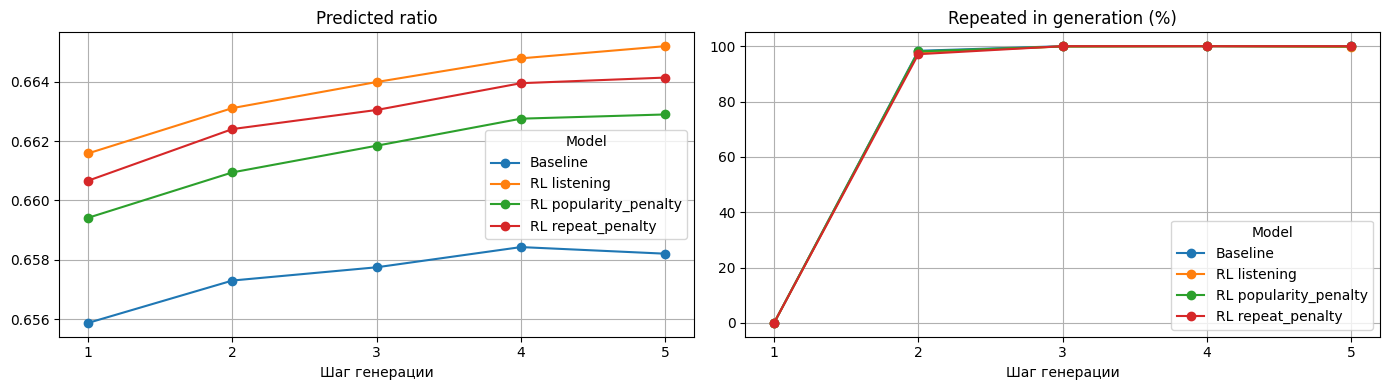

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for column, ax in zip(("Predicted ratio", "Repeated in generation (%)"), axes):
    rollout_metrics[column].unstack("Model").plot(ax=ax, marker="o")
    ax.set_title(column)
    ax.set_xlabel("Шаг генерации")
    ax.set_xticks(range(1, 6))
    ax.grid(True)
plt.tight_layout()
fig.savefig(REPORT_DIR / "rollout_greedy.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


## Контроль: запрет повторов внутри пяти рекомендаций

Запускаем после предыдущего раздела. Используем те же модели и начальные test-контексты. Меняется только декодирование: на очередном шаге маскируем треки, уже выбранные в этой генерации. Знакомые треки из реальной истории допустимы. Веса не обновляются.

Проверяем, как изменятся прогноз награды и попадание первого test-трека в префикс, если убрать зацикливание. Это эффект ограничения декодирования, а не результат нового RL-обучения.

Сравнение с прежним запуском берём из `rollout_5step_greedy`; новый результат сохраняется отдельно в `rollout_5step_greedy_no_repeats`.


In [20]:
from src.rollout import generate_rollouts, evaluate_rollouts

control_tables, control_sequences = {}, {}
for name, run_dir in runs.items():
    print(name)
    if name == "Baseline":
        rollout_model = reference
    else:
        rollout_model, run_vocab, run_config = load_model(run_dir, device)
        assert run_vocab.token_to_item == vocab.token_to_item
        assert run_config["split"] == baseline_config["split"]
    sequences = generate_rollouts(
        rollout_model, reward_contexts, vocab, num_steps=5, avoid_repeats=True,
    )
    control_tables[name] = evaluate_rollouts(
        reference, reward_head, vocab, reward_contexts, sequences,
        statistics, targets=targets, penalty=0.1,
    )
    control_sequences[name] = sequences
    del rollout_model
    clear_memory()

control_metrics = pd.concat(control_tables, names=["Model"])
control_dir = REPORT_DIR / "rollout_5step_greedy_no_repeats"
control_dir.mkdir(parents=True, exist_ok=True)
control_metrics.to_csv(control_dir / "step_metrics.csv")
with open(control_dir / "sequences.json", "w") as f:
    json.dump(control_sequences, f)
with open(control_dir / "config.json", "w") as f:
    json.dump({
        "runs": {name: path.name for name, path in runs.items()},
        "num_steps": 5, "selection": "greedy", "avoid_repeats": True,
        "penalty": 0.1, "baseline_config": baseline_config,
        "history_protocol": "generated IDs appended; observed feedback and query time fixed",
        "control": "same candidates scored with original real context",
        "targets": "first test item, unknown targets remain misses",
        "num_contexts": len(reward_contexts),
    }, f, indent=2)

# Прежний запуск не перезаписываем и не пересчитываем.
previous_dir = rollout_dir
previous_metrics = pd.read_csv(previous_dir / "step_metrics.csv", index_col=["Model", "Step"])
with open(previous_dir / "config.json") as f:
    previous_config = json.load(f)
assert previous_config["baseline_config"]["split"] == baseline_config["split"]
comparison_decoders = pd.concat({
    "Greedy": previous_metrics,
    "No repeats": control_metrics,
}, names=["Decoder"])
comparison_decoders.to_csv(control_dir / "decoder_comparison.csv")
comparison_decoders.xs(5, level="Step")[[
    "Predicted ratio", "Real-context ratio", "Context shift (absolute)",
    "Repeated in generation (%)", "First-target hit@prefix (%)",
    "Mean popularity", "Mean duration (s)",
]]


Baseline


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

RL listening


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

...

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

RL repeat_penalty


Generate rollouts:   0%|          | 0/29 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

Predicted ratio  Real-context ratio  \
Decoder    Model                                                        
Greedy     Baseline                      0.658204            0.656220   
           RL listening                  0.665203            0.662358   
           RL popularity_penalty         0.662900            0.659896   
           RL repeat_penalty             0.664143            0.661302   
No repeats Baseline                      0.654444            0.652873   
           RL listening                  0.659605            0.657514   
           RL popularity_penalty         0.659250            0.656447   
           RL repeat_penalty             0.659828            0.657110   

                                  Context shift (absolute)  \
Decoder    Model                                             
Greedy     Baseline                               0.014328   
           RL listening                           0.014547   
           RL popularity_penalty                  0.014631   
           RL repeat_penalty                      0.014373   
No repeats Baseline                               0.013466   
           RL listening                           0.013720   
           RL popularity_penalty                  0.013360   
           RL repeat_penalty                      0.013075   

                                  Repeated in generation (%)  \
Decoder    Model                                               
Greedy     Baseline                                99.888517   
           RL listening                            99.777035   
           RL popularity_penalty                   99.888517   
           RL repeat_penalty                      100.000000   
No repeats Baseline                                 0.000000   
           RL listening                             0.000000   
           RL popularity_penalty                    0.000000   
           RL repeat_penalty                        0.000000   

                                  First-target hit@prefix (%)  \
Decoder    Model                                                
Greedy     Baseline                                  2.006689   
           RL listening                              2.118172   
           RL popularity_penalty                     2.118172   
           RL repeat_penalty                         2.452620   
No repeats Baseline                                  4.459309   
           RL listening                              4.459309   
           RL popularity_penalty                     4.124861   
           RL repeat_penalty                         4.236343   

                                  Mean popularity  Mean duration (s)  
Decoder    Model                                                      
Greedy     Baseline                      0.092603         207.447046  
           RL listening                  0.102641         201.744705  
           RL popularity_penalty         0.079452         203.249721  
           RL repeat_penalty             0.087487         202.703456  
No repeats Baseline                      0.096169         202.068004  
           RL listening                  0.110110         199.169454  
           RL popularity_penalty         0.080323         201.114827  
           RL repeat_penalty             0.090013         198.494983

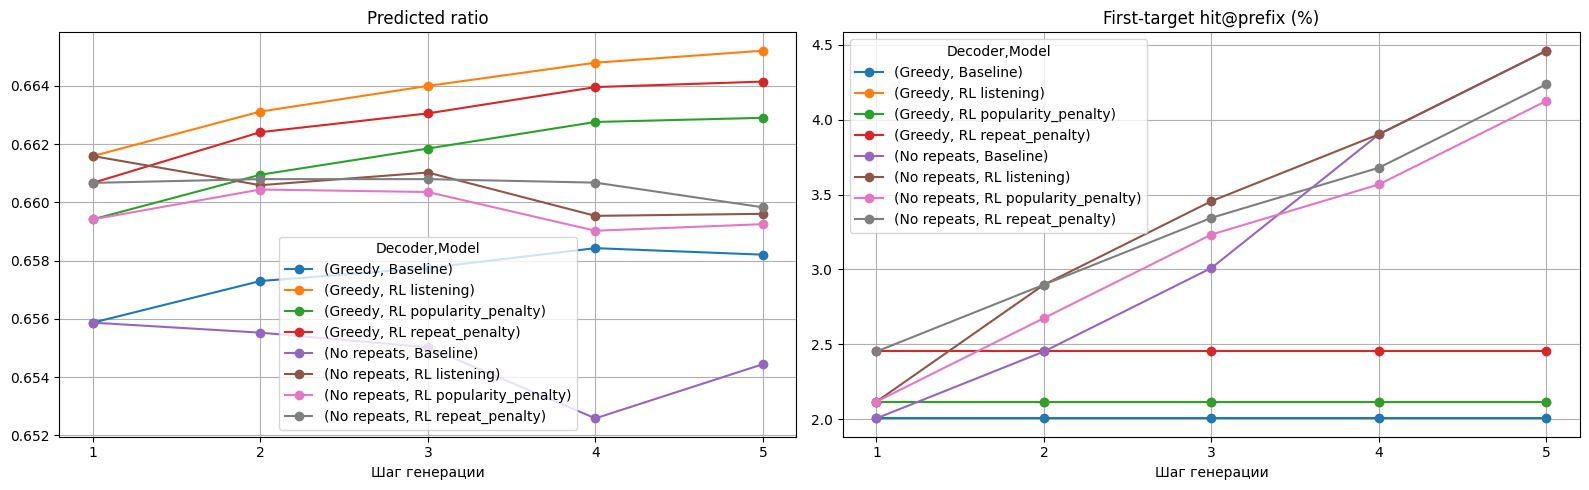

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for column, ax in zip(("Predicted ratio", "First-target hit@prefix (%)"), axes):
    comparison_decoders[column].unstack(["Decoder", "Model"]).plot(ax=ax, marker="o")
    ax.set_title(column)
    ax.set_xlabel("Шаг генерации")
    ax.set_xticks(range(1, 6))
    ax.grid(True)
plt.tight_layout()
fig.savefig(REPORT_DIR / "rollout_no_repeats.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


## RL с наградой за пять шагов

В полном запуске используем готовые модели; обучение включается только флагом RUN_RL_TRAINING.

Начинаем с исходной GPT-2. На каждом train-контексте сэмплируем пять треков. Награда раннего действия учитывает его собственную награду и награды всех последующих шагов (`return-to-go`, gamma=1). Используем среднюю награду на шаг минус средний KL; будущие KL-штрафы тоже учитываются при обучении ранних выборов.

В первом запуске — `repeat_penalty`, сила 0.1, запрет повторов внутри генерации. Нулевые повторы гарантирует маска, а не обучение. Реальные отклики и время запроса фиксированы; ранее выбранные треки влияют только на контекст моделей и проверку повторов.

5000 train-контекстов, 512 validation, 2 эпохи, batch size 32. Это в пять раз больше обучающих действий, чем в одношаговом запуске при том же числе контекстов и эпох; вычислительные бюджеты не равны. Сравниваем исходную, одношаговую и пятишаговую политики при одном декодировании.


In [ ]:
from src.config import RL_MULTISTEP_PARAMS
from src.reinforce import train_reinforce, prepare_rl_contexts
from src.reinforce_multistep import run_multistep_epoch
from src.reward import prepare_track_statistics
from src.evaluation import prepare_evaluation_data, recommend_top_k, evaluate_metrics
from src.rollout import generate_rollouts, evaluate_rollouts

multi_params = RL_MULTISTEP_PARAMS.copy()
torch.manual_seed(multi_params["seed"])
np.random.seed(multi_params["seed"])
multi_policy, multi_vocab, multi_config = load_model(baseline_dir, device)
multi_reference, _, _ = load_model(baseline_dir, device)
multi_reference.requires_grad_(False)
with open(reward_dir / "reward_head.pkl", "rb") as f:
    multi_head = pickle.load(f)
with open(reward_dir / "config.json") as f:
    multi_reward_config = json.load(f)
assert multi_reward_config["backbone_run"] == baseline_dir.name
assert multi_reward_config["split"] == multi_config["split"]

multi_run_name = f"rl_5step_{multi_params['reward_type']}_seed{multi_params['seed']}"
multi_source_dir = ARTIFACTS_DIR / multi_run_name if RUN_RL_TRAINING else find_artifact_dir(multi_run_name)
multi_output_dir = multi_source_dir if RUN_RL_TRAINING else REPORT_DIR / f"evaluation_{multi_run_name}"
multi_output_dir.mkdir(parents=True, exist_ok=True)
multi_experiment = {"baseline_run": baseline_dir.name, "reward_run": reward_dir.name,
                    "baseline_config": multi_config}
print(f"Награда: {multi_params['reward_type']}, шагов: {multi_params['num_steps']}")
print(f"Сохраним в: {multi_output_dir}")


In [23]:
df = load_yambda_data(size=multi_config["training"]["data_size"])
train, val, test = train_val_test_split(df, **multi_config["split"])
del df
clear_memory()
multi_statistics = prepare_track_statistics(train)
multi_train_contexts = prepare_rl_contexts(
    train, multi_vocab, multi_params["train_samples"], multi_params["seed"],
)
multi_val_contexts = prepare_rl_contexts(
    val, multi_vocab, multi_params["val_samples"], multi_params["seed"], context=train,
)

# Test готовим для отчёта; в обучение и выбор чекпоинта он не передаётся.
multi_rank_contexts, multi_targets = prepare_evaluation_data(
    train, val, test, multi_vocab, multi_policy.config.n_positions,
)
columns = ("item_id", "timestamp", "played_ratio_pct")
histories = {
    row.uid: {col: np.asarray(getattr(row, col)) for col in columns}
    for row in train.itertuples(index=False)
}
for row in val.itertuples(index=False):
    for col in columns:
        histories[row.uid][col] = np.concatenate((histories[row.uid][col], getattr(row, col)))
multi_test_contexts = [
    {"history": histories[row.uid], "query_time": int(row.timestamp[0])}
    for row in test.itertuples(index=False) if len(row.item_id)
]
del train, val, test, histories
clear_memory()
print(f"Контексты: train={len(multi_train_contexts)}, val={len(multi_val_contexts)}, test={len(multi_targets)}")


Выбрано 5000 из 3431203 подходящих событий (всего 3677916)
Выбрано 512 из 484422 подходящих событий (всего 584811)
Контексты: train=5000, val=512, test=897


In [24]:
if RUN_RL_TRAINING:
    multi_history = train_reinforce(
        multi_policy, multi_reference, multi_head, multi_vocab,
        multi_train_contexts, multi_val_contexts, multi_statistics,
        multi_params, multi_output_dir, multi_experiment, epoch_runner=run_multistep_epoch,
    )
else:
    checkpoint = torch.load(multi_source_dir / "checkpoints/best.pt", map_location="cpu", weights_only=True)
    multi_policy.load_state_dict(checkpoint["model_state_dict"])
    del checkpoint
    multi_history = pd.read_csv(multi_source_dir / "history.csv")
multi_history


,epoch,val_reward,val_ratio,val_reference_reward,val_total_reward,val_kl,val_loss,val_objective,train_reward,train_ratio,train_reference_reward,train_total_reward,train_kl,train_loss,train_objective
0,0,0.554593,0.606858,0.542223,2.772963,0.000000,0.304462,0.554593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.558702,0.610616,0.542223,2.793511,0.019621,0.375614,0.557721,0.576994,0.632574,0.560657,2.884969,0.006656,0.379994,0.576661
2,2,0.562174,0.613072,0.542223,2.810869,0.052917,0.427610,0.559528,0.581362,0.635678,0.560657,2.906812,0.025633,0.454959,0.580081


In [25]:
one_step_dir = find_artifact_dir(
    f"rl_{multi_params['reward_type']}_seed{multi_params['seed']}"
)
multi_runs = {"Baseline": baseline_dir, "RL 1 step": one_step_dir, "RL 5 steps": multi_source_dir}
multi_rankings, multi_rollouts, multi_sequences = {}, {}, {}
for name, run_dir in multi_runs.items():
    print(name)
    if name == "Baseline":
        eval_model = multi_reference
    elif name == "RL 5 steps":
        eval_model = multi_policy  # train_reinforce уже восстановил лучшую эпоху.
    else:
        eval_model, run_vocab, run_config = load_model(run_dir, device)
        assert run_vocab.token_to_item == multi_vocab.token_to_item
        assert run_config["split"] == multi_config["split"]
    recs = recommend_top_k(eval_model, multi_rank_contexts, multi_vocab, k=20, batch_size=16)
    multi_rankings[name] = evaluate_metrics(recs, multi_targets)
    sequences = generate_rollouts(
        eval_model, multi_test_contexts, multi_vocab,
        num_steps=multi_params["num_steps"], batch_size=16,
        avoid_repeats=multi_params["avoid_repeats"],
    )
    multi_rollouts[name] = evaluate_rollouts(
        multi_reference, multi_head, multi_vocab, multi_test_contexts, sequences,
        multi_statistics, targets=multi_targets, penalty=multi_params["penalty"], batch_size=16,
    )
    multi_sequences[name] = sequences
    del eval_model
    clear_memory()

multi_ranking_metrics = pd.concat(multi_rankings, names=["Model"])
multi_step_metrics = pd.concat(multi_rollouts, names=["Model"])
multi_ranking_metrics.to_csv(multi_output_dir / "test_ranking_comparison.csv")
multi_step_metrics.to_csv(multi_output_dir / "rollout_comparison.csv")
with open(multi_output_dir / "comparison_sequences.json", "w") as f:
    json.dump(multi_sequences, f)
with open(multi_output_dir / "evaluation_config.json", "w") as f:
    json.dump({
        "runs": {name: path.name for name, path in multi_runs.items()},
        "num_steps": multi_params["num_steps"], "selection": "greedy",
        "avoid_repeats": multi_params["avoid_repeats"], "penalty": multi_params["penalty"],
        "num_contexts": len(multi_targets), "split": multi_config["split"],
        "history_protocol": "generated IDs appended; observed feedback and query time fixed",
    }, f, indent=2)
multi_ranking_metrics


Baseline


Evaluation:   0%|          | 0/57 [00:00<?, ?it/s]

Generate rollouts:   0%|          | 0/57 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

RL 1 step


...

RL 5 steps


Evaluation:   0%|          | 0/57 [00:00<?, ?it/s]

Generate rollouts:   0%|          | 0/57 [00:00<?, ?it/s]

Evaluate rollout steps:   0%|          | 0/5 [00:00<?, ?it/s]

Recall@K    NDCG@K     MAP@K
Model      K                               
Baseline   5   0.049052  0.035263  0.030676
           10  0.071349  0.042439  0.033616
           20  0.094760  0.048353  0.035237
RL 1 step  5   0.047938  0.036469  0.032683
           10  0.064660  0.041982  0.035021
           20  0.094760  0.049490  0.037028
RL 5 steps 5   0.051282  0.036806  0.032070
           10  0.065775  0.041588  0.034097
           20  0.093645  0.048635  0.036033

In [26]:
multi_step_metrics.xs(multi_params["num_steps"], level="Step")[[
    "Predicted ratio", "Real-context ratio", "Context shift (absolute)",
    "Repeat-penalized reward", "Repeated in generation (%)",
    "First-target hit@prefix (%)", "Mean popularity", "Mean duration (s)",
]]


,Predicted ratio,Real-context ratio,Context shift (absolute),Repeat-penalized reward,Repeated in generation (%),First-target hit@prefix (%),Mean popularity,Mean duration (s)
Model,,,,,,,,
Baseline,0.654444,0.652873,0.013466,0.580642,0.0,4.459309,0.096169,202.068004
RL 1 step,0.659828,0.657110,0.013075,0.586807,0.0,4.236343,0.090013,198.494983
RL 5 steps,0.661780,0.658437,0.013643,0.590320,0.0,3.901895,0.088628,200.105909


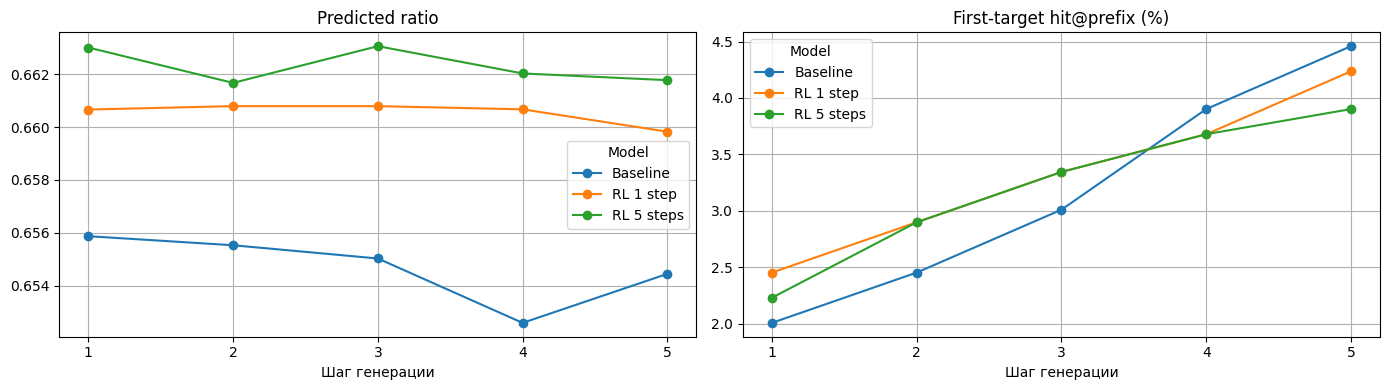

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for column, ax in zip(("Predicted ratio", "First-target hit@prefix (%)"), axes):
    multi_step_metrics[column].unstack("Model").plot(ax=ax, marker="o")
    ax.set_title(column)
    ax.set_xlabel("Шаг генерации")
    ax.set_xticks(range(1, multi_params["num_steps"] + 1))
    ax.grid(True)
plt.tight_layout()
fig.savefig(REPORT_DIR / "multistep_comparison.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


## Одношаговый RL: сила KL-штрафа

При полном запуске ноутбука этот раздел выполняется после предыдущих этапов. Предыдущие обучения не нужны. Проверяем заранее выбранные коэффициенты `0.01`, `0.05`, `0.2` с наградой `repeat_penalty` и прежними данными/настройками. Вариант `0.05` берём из `rl_repeat_penalty_seed42`, обучаем только `0.01` и `0.2`.

Каждая политика начинается с исходной GPT-2. Фиксируем train/validation-контексты и seed. Внутри запуска лучший чекпоинт выбирается по его validation objective; objective с разными KL-коэффициентами не является общей шкалой качества. Все три варианта оцениваем одинаково, не подбирая победителя по test.

Сравнение включает статический top-K, награду жадного top-1 и KL на тех же test-контекстах, знакомые треки, покрытие, сходство списков и популярность. Пятишаговое обучение здесь не повторяется.


In [28]:
from src.config import RL_KL_VALUES
from src.reinforce import prepare_rl_contexts, train_reinforce
from src.reward import prepare_track_statistics
from src.evaluation import prepare_evaluation_contexts, evaluate_policy

sweep_params = RL_PARAMS.copy()
sweep_params.update(reward_type="repeat_penalty", kl_coef=0.05)
sweep_reference, sweep_vocab, sweep_config = load_model(baseline_dir, device)
sweep_reference.requires_grad_(False)
with open(reward_dir / "reward_head.pkl", "rb") as f:
    sweep_head = pickle.load(f)
with open(reward_dir / "config.json") as f:
    sweep_reward_config = json.load(f)
assert sweep_reward_config["backbone_run"] == baseline_dir.name
assert sweep_reward_config["split"] == sweep_config["split"]

sweep_runs = {0.05: find_artifact_dir("rl_repeat_penalty_seed42")}
with open(sweep_runs[0.05] / "experiment_config.json") as f:
    existing_config = json.load(f)
assert existing_config["rl"] == sweep_params, "Настройки готового KL=0.05 отличаются"
assert existing_config["split"] == sweep_config["split"]
sweep_dir = REPORT_DIR / "kl_sweep_repeat_penalty_seed42"
sweep_dir.mkdir(parents=True, exist_ok=True)


In [29]:
df = load_yambda_data(size=sweep_config["training"]["data_size"])
train, val, test = train_val_test_split(df, **sweep_config["split"])
del df
clear_memory()
sweep_statistics = prepare_track_statistics(train)
sweep_train_contexts = prepare_rl_contexts(
    train, sweep_vocab, sweep_params["train_samples"], sweep_params["seed"],
)
sweep_val_contexts = prepare_rl_contexts(
    val, sweep_vocab, sweep_params["val_samples"], sweep_params["seed"], context=train,
)
sweep_test_contexts, sweep_targets = prepare_evaluation_contexts(train, val, test)
del train, val, test
clear_memory()
print(f"Контексты: train={len(sweep_train_contexts)}, val={len(sweep_val_contexts)}, test={len(sweep_targets)}")


Выбрано 5000 из 3431203 подходящих событий (всего 3677916)
Выбрано 512 из 484422 подходящих событий (всего 584811)
Контексты: train=5000, val=512, test=897


In [30]:
# Запускаем только два новых одношаговых обучения.
for coefficient in RL_KL_VALUES:
    if coefficient == 0.05:
        continue
    run_params = {**sweep_params, "kl_coef": coefficient}
    torch.manual_seed(run_params["seed"])
    np.random.seed(run_params["seed"])
    suffix = f"{coefficient:g}".replace(".", "p")
    run_dir = ARTIFACTS_DIR / f"rl_repeat_penalty_kl{suffix}_seed{sweep_params['seed']}"
    if not RUN_RL_TRAINING:
        sweep_runs[coefficient] = find_artifact_dir(run_dir.name)
        continue
    sweep_policy, _, _ = load_model(baseline_dir, device)
    print(f"KL={coefficient}, сохраняем в {run_dir}")
    train_reinforce(
        sweep_policy, sweep_reference, sweep_head, sweep_vocab,
        sweep_train_contexts, sweep_val_contexts, sweep_statistics, run_params, run_dir,
        {"baseline_run": baseline_dir.name, "reward_run": reward_dir.name,
         "baseline_config": sweep_config},
    )
    sweep_runs[coefficient] = run_dir
    del sweep_policy
    clear_memory()

validation_rows = []
for coefficient in RL_KL_VALUES:
    run_history = pd.read_csv(sweep_runs[coefficient] / "history.csv")
    best = run_history.loc[run_history["val_objective"].idxmax()]
    validation_rows.append({"KL coefficient": coefficient, **best.to_dict()})
sweep_validation = pd.DataFrame(validation_rows).set_index("KL coefficient")
sweep_validation.to_csv(sweep_dir / "validation_summary.csv")
sweep_validation[["epoch", "val_reward", "val_ratio", "val_kl", "val_objective"]]


,epoch,val_reward,val_ratio,val_kl,val_objective
KL coefficient,,,,,
0.01,2.0,0.558963,0.612088,0.082318,0.558140
0.05,2.0,0.556323,0.610425,0.040541,0.554296
0.20,1.0,0.552386,0.607464,0.005582,0.551269


In [31]:
sweep_rankings, sweep_behaviors = {}, {}
sweep_models = {"Baseline": baseline_dir, **{f"KL={c:g}": sweep_runs[c] for c in RL_KL_VALUES}}
for name, run_dir in sweep_models.items():
    print(name)
    if name == "Baseline":
        eval_model = sweep_reference
    else:
        eval_model, run_vocab, run_config = load_model(run_dir, device)
        assert run_vocab.token_to_item == sweep_vocab.token_to_item
        assert run_config["split"] == sweep_config["split"]
    sweep_rankings[name], sweep_behaviors[name] = evaluate_policy(
        eval_model, sweep_reference, sweep_head, sweep_vocab,
        sweep_test_contexts, sweep_targets, sweep_statistics, sweep_params,
    )
    del eval_model
    clear_memory()

sweep_ranking_metrics = pd.concat(sweep_rankings, names=["Model"])
sweep_behavior = pd.DataFrame.from_dict(sweep_behaviors, orient="index")
sweep_behavior.index.name = "Model"
sweep_ranking_metrics.to_csv(sweep_dir / "test_ranking_metrics.csv")
sweep_behavior.to_csv(sweep_dir / "test_behavior_metrics.csv")
with open(sweep_dir / "config.json", "w") as f:
    json.dump({
        "kl_values": list(RL_KL_VALUES), "base_params": sweep_params,
        "runs": {name: path.name for name, path in sweep_models.items()},
        "reused_run": sweep_runs[0.05].name, "baseline_config": sweep_config,
        "num_test_contexts": len(sweep_targets),
        "selection": "top-K; reward for greedy top-1; KL over all real tracks",
    }, f, indent=2)
sweep_ranking_metrics


Baseline


Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

Reward and KL:   0%|          | 0/29 [00:00<?, ?it/s]

KL=0.01


Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

...

Reward and KL:   0%|          | 0/29 [00:00<?, ?it/s]

KL=0.2


Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

Reward and KL:   0%|          | 0/29 [00:00<?, ?it/s]

Recall@K    NDCG@K     MAP@K
Model    K                               
Baseline 5   0.049052  0.035263  0.030676
         10  0.071349  0.042439  0.033616
         20  0.094760  0.048353  0.035237
KL=0.01  5   0.047938  0.037347  0.033816
         10  0.066890  0.043489  0.036362
         20  0.090301  0.049416  0.037992
KL=0.05  5   0.047938  0.036469  0.032683
         10  0.064660  0.041982  0.035021
         20  0.094760  0.049490  0.037028
KL=0.2   5   0.052397  0.037540  0.032702
         10  0.069119  0.042916  0.034903
         20  0.099220  0.050423  0.036909

In [32]:
sweep_behavior


,Predicted ratio@1,Reward@1,KL,Seen@20 (%),Catalog coverage@20 (%),Overlap@20 (%),Mean popularity@20
Model,,,,,,,
Baseline,0.655870,0.570028,0.000000,68.316611,11.647862,0.493373,0.097205
KL=0.01,0.663903,0.578507,0.080912,66.287625,11.345215,0.492975,0.087196
KL=0.05,0.660667,0.574825,0.039994,67.224080,11.491321,0.481516,0.090119
KL=0.2,0.657638,0.571351,0.005580,68.071349,11.665256,0.478343,0.094031


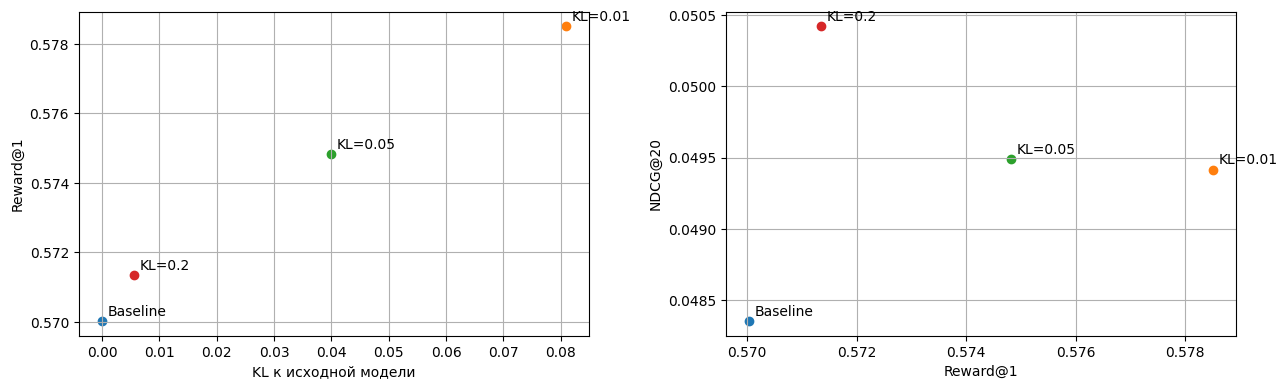

In [33]:
plot_table = sweep_behavior.join(sweep_ranking_metrics.xs(20, level="K"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, row in plot_table.iterrows():
    axes[0].scatter(row["KL"], row["Reward@1"])
    axes[0].annotate(name, (row["KL"], row["Reward@1"]), xytext=(4, 4), textcoords="offset points")
    axes[1].scatter(row["Reward@1"], row["NDCG@K"])
    axes[1].annotate(name, (row["Reward@1"], row["NDCG@K"]), xytext=(4, 4), textcoords="offset points")
axes[0].set(xlabel="KL к исходной модели", ylabel="Reward@1")
axes[1].set(xlabel="Reward@1", ylabel="NDCG@20")
for ax in axes:
    ax.grid(True)
plt.tight_layout()
fig.savefig(sweep_dir / "kl_tradeoff.png", dpi=150, bbox_inches="tight")
fig.savefig(REPORT_DIR / "kl_tradeoff.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


## Сводка для отчёта

Сохраняем исходные таблицы трёх наград, их истории и общую сводку. Все экспортированные рисунки и таблицы находятся в REPORT_DIR. Для завершения отчёта передайте эту папку после запуска; веса моделей пересылать повторно не требуется.


In [34]:
reward_run_names = {
    "RL listening": "rl_listening_seed42",
    "RL popularity penalty": "rl_popularity_penalty_seed42",
    "RL repeat penalty": "rl_repeat_penalty_seed42",
}
reward_ranking_tables, reward_behavior_rows, reward_histories = {}, {}, {}
for label, run_name in reward_run_names.items():
    directory = find_artifact_dir(run_name)
    rankings = pd.read_csv(directory / "test_ranking_metrics.csv", index_col=["Model", "K"])
    behaviors = pd.read_csv(directory / "test_behavior_metrics.csv", index_col="Model")
    reward_ranking_tables[label] = rankings.xs("RL", level="Model")
    reward_behavior_rows[label] = behaviors.loc["RL"].to_dict()
    reward_histories[label] = pd.read_csv(directory / "history.csv")
    if "Baseline" not in reward_ranking_tables:
        reward_ranking_tables["Baseline"] = rankings.xs("Baseline", level="Model")
        reward_behavior_rows["Baseline"] = behaviors.loc["Baseline"].to_dict()
rl_reward_ranking = pd.concat(reward_ranking_tables, names=["Model"])
rl_reward_behavior = pd.DataFrame.from_dict(reward_behavior_rows, orient="index")
rl_reward_behavior.index.name = "Model"
rl_reward_ranking.to_csv(REPORT_DIR / "rl_rewards_ranking.csv")
rl_reward_behavior.to_csv(REPORT_DIR / "rl_rewards_behavior.csv")
rl_reward_ranking


Recall@K    NDCG@K     MAP@K
Model                 K                               
RL listening          5   0.049052  0.035812  0.031420
                      10  0.065775  0.041216  0.033647
                      20  0.094760  0.048549  0.035662
Baseline              5   0.049052  0.035263  0.030676
                      10  0.071349  0.042439  0.033616
                      20  0.094760  0.048353  0.035237
RL popularity penalty 5   0.046823  0.034969  0.031011
                      10  0.064660  0.040708  0.033360
                      20  0.095875  0.048699  0.035605
RL repeat penalty     5   0.047938  0.036469  0.032683
                      10  0.064660  0.041982  0.035021
                      20  0.094760  0.049490  0.037028

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, frame in reward_histories.items():
    axes[0].plot(frame.epoch, frame.val_ratio, marker="o", label=label)
    axes[1].plot(frame.epoch, frame.val_kl, marker="o", label=label)
axes[0].set(title="Validation: прогноз доли прослушивания", xlabel="Эпоха", ylabel="Predicted ratio")
axes[1].set(title="Validation: отклонение от reference", xlabel="Эпоха", ylabel="KL")
for ax in axes:
    ax.grid(True)
    ax.legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / "rl_training.svg", bbox_inches="tight")
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(9, 4))
rl_reward_ranking["Recall@K"].unstack("Model").plot(ax=ax, marker="o")
ax.set(ylabel="Recall@K", title="Релевантность: три функции награды")
ax.grid(True)
fig.tight_layout()
fig.savefig(REPORT_DIR / "rl_relevance.svg", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Готово: таблицы и SVG для отчёта в {REPORT_DIR}")
